# 02fhycom: ocean currents for the Bering Strait, year 2023 (analysis system)

PF9, step 3 (later years). Same job as 02hycomdownload, but for a year after 2015, which comes from a different HYCOM system: the **GOFS 3.1 analysis GLBy0.08 expt_93.0** (December 2018 to September 2024) instead of the reanalysis. Free, no login, no Copernicus.

Differences from the reanalysis notebooks:
- Currents and temperature are two separate datasets on the server (`uv3z` and `ts3z`), so each snapshot is two requests.
- Longitudes run 0 to 360, so the window comes in one piece (no split at 180°).
- The exact server path is not certain, so Section 2 tries a short list of paths and keeps the first that works.
- Each new file is checked against a 2015 file: same longitudes, latitudes and depths. If the grid differs, the file is interpolated onto the 2015 grid (reported), so 04hycommonthly and 05particles can mix all years.
- The analysis is not the same model run as the reanalysis: there can be a jump between 2015 and the later years that is not real. The page will label the two eras.

Year **2023**: February, May, August, November, every 2 days at 00 UTC (61 snapshots, about 1.5 to 2 hours). Safe to stop (interrupt the kernel) and run again later: files already saved are skipped.


## Section 0. Settings

Lines marked `# <-` can be changed.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
OUT_DIR = PROJECT_DIR / "data" / "raw" / "hycom"

YEARS = [2023]  # <- the year this notebook downloads (2019 to 2023 are fully inside the analysis; 2024 only to September)
MONTHS = [2, 5, 8, 11]  # <- February (winter ice), May (break-up), August (open water), November (freeze-up)
DAY_STEP = 2  # <- one snapshot every DAY_STEP days (1 = every day)
HOUR = 0  # <- snapshot hour in UTC (the analysis has 0, 3, 6, ... 21)
MAX_TIME_OFFSET_H = 1.5  # <- if the server returns a time further than this from the one asked for, the snapshot counts as missing

NORTH = 72.0  # <- window, degrees north (same as the reanalysis notebooks)
SOUTH = 62.0  # <- window, degrees north
WEST = 175.0  # <- window, degrees east (Chukotka side)
EAST = 205.0  # <- window, degrees east, 205 = 155°W (Alaska side)
MAX_DEPTH_M = 100  # <- keep only depth levels down to this depth
PAD_DEG = 0.1  # <- the request is this much wider on each side, so the edge cells of the 2015 grid are always included

BASE_URL = "https://ncss.hycom.org/thredds/ncss"  # <- HYCOM subsetting service
UV_PATHS = ["GLBy0.08/expt_93.0/uv3z", "GLBy0.08/expt_93.0/uv3z/{year}", "GLBy0.08/expt_93.0_uv3z"]  # <- tried in order for currents (water_u, water_v)
TS_PATHS = ["GLBy0.08/expt_93.0/ts3z", "GLBy0.08/expt_93.0/ts3z/{year}", "GLBy0.08/expt_93.0_ts3z"]  # <- tried in order for temperature (water_temp)
SOURCE = "HYCOM GOFS 3.1 analysis GLBy0.08 expt_93.0"  # <- written into each file
REFERENCE_GLOB = "hycom_2015*.nc"  # <- an existing reanalysis file whose grid the new files must match
TIMEOUT_S = 300  # <- give up on one request after this many seconds
RETRIES = 3  # <- tries per request

## Section 1. Libraries and the 2015 reference grid

In [2]:
import time
import datetime as dt
import numpy as np
import pandas as pd
import requests
import xarray as xr
import matplotlib.pyplot as plt

OUT_DIR.mkdir(parents=True, exist_ok=True)
TMP_DIR = OUT_DIR / "_tmp"
TMP_DIR.mkdir(exist_ok=True)


def snapshot_times(years, months, day_step, hour):
    out = []
    for y in years:
        for m in months:
            day = dt.datetime(y, m, 1, hour)
            while day.month == m:
                out.append(day)
                day = day + dt.timedelta(days=day_step)
    return out


def request_url(path, variables, when):
    var_part = "&".join(f"var={v}" for v in variables)
    return f"{BASE_URL}/{path.format(year=when.year)}?{var_part}&north={NORTH + PAD_DEG}&south={SOUTH - PAD_DEG}&west={WEST - PAD_DEG}&east={EAST + PAD_DEG}&horizStride=1&time={when:%Y-%m-%dT%H:%M:%SZ}&addLatLon=true&accept=netcdf4"


def fetch(url, dest):
    last_error = None
    for attempt in range(1, RETRIES + 1):
        try:
            t0 = time.perf_counter()
            with requests.get(url, timeout=TIMEOUT_S, stream=True) as r:
                if r.status_code != 200:
                    last_error = f"HTTP {r.status_code}: {r.text[:200]}"
                    if r.status_code in (400, 404):
                        break
                    continue
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            return time.perf_counter() - t0, dest.stat().st_size, None
        except requests.RequestException as e:
            last_error = str(e)
            time.sleep(5 * attempt)
    return None, 0, last_error


def open_trim(path):
    ds = xr.open_dataset(path, engine="h5netcdf")
    rename = {k: v for k, v in {"longitude": "lon", "latitude": "lat"}.items() if k in ds.coords or k in ds.dims}
    ds = ds.rename(rename)
    if "depth" in ds.dims:
        ds = ds.sel(depth=ds.depth[ds.depth <= MAX_DEPTH_M])
    ds = ds.assign_coords(lon=ds["lon"] % 360).sortby("lon").sortby("lat")
    return ds.load()


def returned_time(ds):
    if "time" not in ds.coords:
        return None
    return pd.Timestamp(np.atleast_1d(ds["time"].values)[0]).to_pydatetime()


def same_grid(ds, ref):
    """For each of lon, lat, depth: does the new file contain every 2015 grid point (to 0.001)?"""
    out = {}
    for c in ["lon", "lat", "depth"]:
        a, b = ds[c].values, ref[c].values
        idx = np.clip(np.searchsorted(a, b), 1, len(a) - 1) if len(a) > 1 else np.zeros(len(b), int)
        near = np.minimum(np.abs(a[idx] - b), np.abs(a[idx - 1] - b)) if len(a) > 1 else np.abs(a[0] - b)
        out[c] = bool(np.all(near < 1e-3))
    return out


def to_reference_grid(ds, ref):
    """Pick exactly the 2015 grid points if they are all there, otherwise interpolate (counted and reported)."""
    g = same_grid(ds, ref)
    if all(g.values()):
        ds = ds.sel(lon=ref["lon"].values, lat=ref["lat"].values, depth=ref["depth"].values, method="nearest")
        return ds.assign_coords(lon=ref["lon"].values, lat=ref["lat"].values, depth=ref["depth"].values), False
    ds = ds.interp(lon=ref["lon"].values, lat=ref["lat"].values, depth=ref["depth"].values)
    ds = ds.astype({v: "float32" for v in ds.data_vars})
    return ds, True


def save(ds, dest):
    ds.attrs["source"] = SOURCE
    enc = {v: {"zlib": True, "complevel": 4} for v in ds.data_vars}
    ds.to_netcdf(dest, engine="h5netcdf", encoding=enc)
    ds.close()


ref_files = sorted(OUT_DIR.glob(REFERENCE_GLOB))
assert ref_files, f"No reference file {REFERENCE_GLOB} in {OUT_DIR}: run the reanalysis notebooks first"
ref = open_trim(ref_files[0])
print("Reference grid from", ref_files[0].name, ":", ref.sizes["lon"], "x", ref.sizes["lat"], "cells,", ref.sizes["depth"], "depth levels")

Reference grid from hycom_20150201.nc : 376 x 251 cells, 20 depth levels


## Section 2. Probe: find the server paths with one snapshot

Tries each path in `UV_PATHS` and `TS_PATHS` for the first snapshot and keeps the first that answers with the right variables. Then checks the time the server returned and compares the grid with the 2015 reference file.

In [3]:
probe_time = snapshot_times(YEARS[:1], MONTHS[:1], DAY_STEP, HOUR)[0]
print("Probe snapshot:", probe_time)


def find_path(paths, variables, label):
    for p in paths:
        url = request_url(p, variables, probe_time)
        secs, size, err = fetch(url, TMP_DIR / f"probe_{label}.nc")
        if err is not None:
            print(f"  {label}: {p} -> refused ({err[:120]})")
            continue
        try:
            ds = open_trim(TMP_DIR / f"probe_{label}.nc")
        except Exception as e:
            print(f"  {label}: {p} -> not a readable NetCDF file ({e})")
            continue
        if not all(v in ds.data_vars for v in variables):
            print(f"  {label}: {p} -> missing variables, has {list(ds.data_vars)}")
            continue
        print(f"  {label}: {p} -> OK, {round(size / 1e6, 2)} MB in {round(secs, 1)} s")
        return p, ds, secs, size
    raise RuntimeError(f"No working path for {label}. Check the HYCOM catalog (https://ncss.hycom.org/thredds/catalogs/GLBy0.08/expt_93.0.html) and add the right path to the settings.")


uv_path, probe_uv, s_uv, z_uv = find_path(UV_PATHS, ["water_u", "water_v"], "uv")
ts_path, probe_ts, s_ts, z_ts = find_path(TS_PATHS, ["water_temp"], "ts")
probe_secs = s_uv + s_ts
probe_mb = (z_uv + z_ts) / 1e6

for label, ds in [("uv", probe_uv), ("ts", probe_ts)]:
    t = returned_time(ds)
    off = abs((t - probe_time).total_seconds()) / 3600 if t else None
    print(f"{label}: server time {t}, {round(off, 2) if off is not None else '?'} h from the time asked for")
    print(f"{label}: grid {ds.sizes['lon']} x {ds.sizes['lat']}, {ds.sizes['depth']} depth levels; contains every 2015 grid point: {same_grid(ds, ref)}")

probe_uv_g, reg_uv = to_reference_grid(probe_uv, ref)
probe_ts_g, reg_ts = to_reference_grid(probe_ts, ref)
probe = xr.merge([probe_uv_g[["water_u", "water_v"]], probe_ts_g[["water_temp"]].assign_coords(time=probe_uv_g["time"].values)], compat="override", join="exact")
regridded = reg_uv or reg_ts
print("Regridded to the 2015 grid:", regridded)

Probe snapshot: 2023-02-01 00:00:00
  uv: GLBy0.08/expt_93.0/uv3z -> OK, 1.3 MB in 88.6 s
  ts: GLBy0.08/expt_93.0/ts3z -> OK, 0.46 MB in 37.9 s
uv: server time 2023-02-01 00:00:00, 0.0 h from the time asked for
uv: grid 379 x 256, 20 depth levels; contains every 2015 grid point: {'lon': True, 'lat': True, 'depth': True}
ts: server time 2023-02-01 00:00:00, 0.0 h from the time asked for
ts: grid 379 x 256, 20 depth levels; contains every 2015 grid point: {'lon': True, 'lat': True, 'depth': True}
Regridded to the 2015 grid: False


Surface speed: median 0.174 m/s, 95th percentile 0.322 m/s
Surface temperature: median -1.72 °C
Land/water mask agrees with 2015 in 100.0 % of cells (should be close to 100)


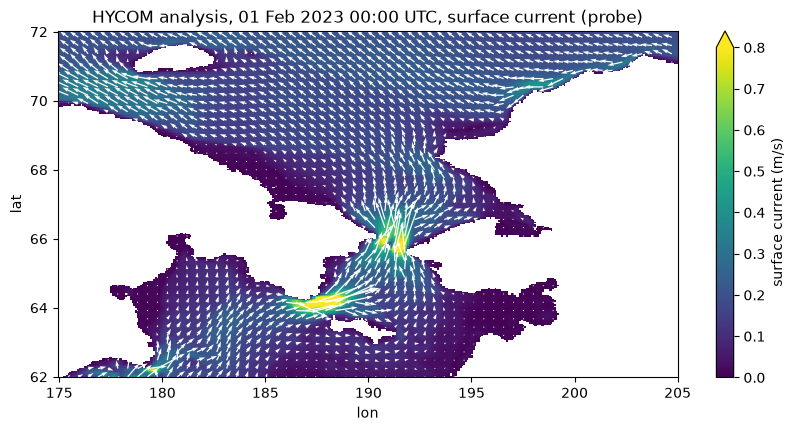

In [4]:
surf = probe.isel(time=0, depth=0) if "time" in probe.dims else probe.isel(depth=0)
speed = np.hypot(surf["water_u"], surf["water_v"])
print("Surface speed: median", round(float(speed.median()), 3), "m/s, 95th percentile", round(float(speed.quantile(0.95)), 3), "m/s")
print("Surface temperature: median", round(float(surf["water_temp"].median()), 2), "°C")

ref_surf = ref.isel(time=0, depth=0) if "time" in ref.dims else ref.isel(depth=0)
same_land = int((np.isnan(surf["water_u"].values) == np.isnan(ref_surf["water_u"].values)).mean() * 1000) / 10
print("Land/water mask agrees with 2015 in", same_land, "% of cells (should be close to 100)")

fig, ax = plt.subplots(figsize=(10, 4.5))
speed.plot(ax=ax, x="lon", y="lat", cmap="viridis", vmin=0, vmax=0.8, cbar_kwargs={"label": "surface current (m/s)"})
step = 6
q = surf.isel(lat=slice(None, None, step), lon=slice(None, None, step))
ax.quiver(q["lon"], q["lat"], q["water_u"], q["water_v"], color="white", scale=12, width=0.002)
ax.set_title(f"HYCOM analysis, {probe_time:%d %b %Y %H:%M} UTC, surface current (probe)")
plt.show()

## Section 3. Download the year

One file per snapshot, `hycom_YYYYMMDD.nc`, in the same folder and layout as the reanalysis files (water_u, water_v, water_temp on the 2015 grid, top `MAX_DEPTH_M` metres). Existing files are skipped. A failed snapshot is listed at the end and can be retried by running this section again.

In [5]:
times = snapshot_times(YEARS, MONTHS, DAY_STEP, HOUR)
print("Snapshots to get:", len(times), "| currents from", uv_path, "| temperature from", ts_path)

log = []
failed = []
regrid_count = 0
t_start = time.perf_counter()
for i, when in enumerate(times):
    dest = OUT_DIR / f"hycom_{when:%Y%m%d}.nc"
    if dest.exists():
        continue
    s1, z1, e1 = fetch(request_url(uv_path, ["water_u", "water_v"], when), TMP_DIR / "part_uv.nc")
    s2, z2, e2 = (None, 0, "skipped") if e1 else fetch(request_url(ts_path, ["water_temp"], when), TMP_DIR / "part_ts.nc")
    if e1 or e2:
        failed.append((when, e1 or e2))
        print(f"{when:%Y-%m-%d} FAILED: {e1 or e2}")
        continue
    uv = open_trim(TMP_DIR / "part_uv.nc")
    ts = open_trim(TMP_DIR / "part_ts.nc")
    bad_time = None
    for label, ds in [("uv", uv), ("ts", ts)]:
        t = returned_time(ds)
        if t is None or abs((t - when).total_seconds()) / 3600 > MAX_TIME_OFFSET_H:
            bad_time = f"{label} time {t} not near {when}"
    if bad_time:
        failed.append((when, bad_time))
        print(f"{when:%Y-%m-%d} MISSING on the server: {bad_time}")
        continue
    uv, reg_uv = to_reference_grid(uv, ref)
    ts, reg_ts = to_reference_grid(ts, ref)
    ts = ts.assign_coords(time=uv["time"].values)
    ds = xr.merge([uv[["water_u", "water_v"]], ts[["water_temp"]]], compat="override", join="exact")
    regrid_count += int(reg_uv or reg_ts)
    save(ds, dest)
    secs_i = (s1 or 0) + (s2 or 0)
    mb_i = (z1 + z2) / 1e6
    log.append({"time": when, "seconds": secs_i, "downloaded_mb": mb_i, "saved_mb": dest.stat().st_size / 1e6})
    done = len(log)
    elapsed = time.perf_counter() - t_start
    left = (len(times) - i - 1) * elapsed / done
    print(f"{when:%Y-%m-%d}  {secs_i:5.1f} s  {mb_i:5.1f} MB  ({done} done, about {left / 60:.0f} min left)")

print("Finished in", round((time.perf_counter() - t_start) / 60, 1), "min;", len(log), "new files,", len(failed), "failed;", regrid_count, "regridded")

Snapshots to get: 61 | currents from GLBy0.08/expt_93.0/uv3z | temperature from GLBy0.08/expt_93.0/ts3z
2023-02-01   12.3 s    1.8 MB  (1 done, about 13 min left)
2023-02-03   43.9 s    1.8 MB  (2 done, about 28 min left)
2023-02-05   43.8 s    1.7 MB  (3 done, about 33 min left)
2023-02-07   88.7 s    1.7 MB  (4 done, about 45 min left)
2023-02-09   29.4 s    1.6 MB  (5 done, about 41 min left)
2023-02-11   60.1 s    1.7 MB  (6 done, about 43 min left)
2023-02-13   32.5 s    1.6 MB  (7 done, about 40 min left)
2023-02-15   24.4 s    1.6 MB  (8 done, about 37 min left)
2023-02-17   23.3 s    1.7 MB  (9 done, about 35 min left)
2023-02-19   24.9 s    1.6 MB  (10 done, about 33 min left)
2023-02-21   23.1 s    1.6 MB  (11 done, about 31 min left)
2023-02-23   33.1 s    1.8 MB  (12 done, about 30 min left)
2023-02-25   22.7 s    1.9 MB  (13 done, about 29 min left)
2023-02-27   49.4 s    1.7 MB  (14 done, about 29 min left)
2023-05-01   34.4 s    1.7 MB  (15 done, about 28 min left)
2023-

## Section 4. Check the year

In [6]:
expected = [f"hycom_{t:%Y%m%d}.nc" for t in snapshot_times(YEARS, MONTHS, DAY_STEP, HOUR)]
present = [n for n in expected if (OUT_DIR / n).exists()]
missing = [n for n in expected if not (OUT_DIR / n).exists()]
print("Snapshots present:", len(present), "of", len(expected))
if missing:
    print("Missing (run Section 3 again; if the server lacks a day, it stays missing and 04 uses the others):", missing)

if present:
    chk = xr.open_dataset(OUT_DIR / present[-1], engine="h5netcdf")
    print("Last file:", present[-1], dict(chk.sizes), list(chk.data_vars), "|", chk.attrs.get("source"))
    print("Same grid as 2015:", same_grid(chk, ref))
    chk.close()

log_df = pd.DataFrame(log)
if len(log_df):
    print("Per snapshot this run:", round(log_df["seconds"].mean(), 1), "s,", round(log_df["downloaded_mb"].mean(), 1), "MB downloaded,", round(log_df["saved_mb"].mean(), 1), "MB saved")
if failed:
    print("Failed snapshots:", [(f"{t:%Y-%m-%d}", str(e)[:80]) for t, e in failed])
print()
print("Next: run 04hycommonthly (all years), then 05particles with YEAR =", YEARS[0], ", then add", YEARS[0], "to TRACK_YEARS on the page.")
log_df

Snapshots present: 61 of 61
Last file: hycom_20231129.nc {'time': 1, 'depth': 20, 'lat': 251, 'lon': 376} ['water_u', 'water_v', 'water_temp'] | HYCOM GOFS 3.1 analysis GLBy0.08 expt_93.0
Same grid as 2015: {'lon': True, 'lat': True, 'depth': True}
Per snapshot this run: 36.3 s, 2.1 MB downloaded, 3.2 MB saved

Next: run 04hycommonthly (all years), then 05particles with YEAR = 2023 , then add 2023 to TRACK_YEARS on the page.


,time,seconds,downloaded_mb,saved_mb
0,2023-02-01,12.314373,1.758218,2.335325
1,2023-02-03,43.908226,1.769726,2.369931
2,2023-02-05,43.844228,1.699354,2.235677
3,2023-02-07,88.683909,1.660182,2.141950
4,2023-02-09,29.353136,1.581280,2.044431
...,...,...,...,...
56,2023-11-21,46.622034,2.390127,3.647836
57,2023-11-23,26.122651,2.386605,3.618617
58,2023-11-25,31.195775,2.350718,3.491609
59,2023-11-27,34.820750,2.311109,3.431644


___
**END**